# Lab 5: Motor parameter identification

I ran the step-response experiment on both drive wheels of robot A17: wheel 3 (big wheel, port M3, encoder E3) and wheel 4 (small wheel, port M4, encoder E4). The robot was on a stand, so the wheels spun freely. For every PWM level from -100 % to +100 % in 5 % steps, the program in `motor_identification.qrs` applied the step, logged time and encoder angle for 2 s, and wrote the battery voltage into the file header. The raw files are in `motor_data/`.

Model from the lecture, for a voltage step $U$ from rest:

$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}, \qquad U = \frac{PWM}{100}\,U_{battery}$$

In [1]:
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

COLOR = {3: "#1f77b4", 4: "#e8710a"}
MARKER = {3: "o", 4: "s"}

In [2]:
DATA_DIR = "motor_data"

# in Colab: upload the zip with the robot files
if not os.path.isdir(DATA_DIR):
    from google.colab import files
    uploaded = files.upload()
    with zipfile.ZipFile(list(uploaded)[0]) as z:
        z.extractall(DATA_DIR)


def read_run(wheel, pwm):
    path = f"{DATA_DIR}/wheel_{wheel}_v_{pwm}.txt"
    with open(path) as f:
        battery = float([l for l in f if l.startswith("# battery_voltage")][0].split(":")[1])
    t_ms, angle_deg = np.loadtxt(path, comments="#", unpack=True)
    return t_ms / 1000, np.radians(angle_deg), battery


WHEELS = [3, 4]
LEVELS = list(range(-100, 0, 5)) + list(range(5, 105, 5))
data = {(w, p): read_run(w, p) for w in WHEELS for p in LEVELS}
print(len(data), "runs loaded")

Saving motor_data_A17_0vbe16yx.zip to motor_data_A17_0vbe16yx.zip
80 runs loaded


## 1. Fitting $\theta(t)$

Each run is fitted with `curve_fit`. Time is not shifted, because t = 0 in the files is the moment the power was applied. As a starting guess for $\omega_{ss}$ I use the slope of the second half of the curve, since with `p0=[8, 0.1]` from the example the fit for wheel 4 at 100 % did not converge.

In [3]:
def theta_model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))


rows = []
for (w, p), (t, theta, battery) in data.items():
    half = len(t) // 2
    w_guess = np.polyfit(t[half:], theta[half:], 1)[0]
    (w_ss, T_m), _ = optimize.curve_fit(theta_model, t, theta, p0=[w_guess, 0.2],
                                        bounds=([-50, 0.001], [50, 2]))
    rows.append({"wheel": w, "PWM": p, "U": p / 100 * battery, "w_ss": w_ss, "T_m": T_m})

res = pd.DataFrame(rows)

## 2. $T_m$ and $\omega_{ss}$ for every PWM level

In [4]:
names = {"U": "U [V]", "w_ss": "ω_ss [rad/s]", "T_m": "T_m [s]"}
table = pd.concat({f"Wheel {w}": res[res.wheel == w].set_index("PWM")[list(names)].round({"U": 2, "w_ss": 2, "T_m": 3}).rename(columns=names)
                   for w in WHEELS}, axis=1)
table.index.name = "PWM [%]"
pd.set_option("display.max_rows", 100)
table

Wheel 3                      Wheel 4                     
          U [V] ω_ss [rad/s] T_m [s]   U [V] ω_ss [rad/s] T_m [s]
PWM [%]                                                          
-100     -11.31       -14.66   0.052  -11.30       -13.94   0.042
-95      -10.75       -14.28   0.078  -10.76       -13.45   0.055
-90      -10.18       -13.62   0.107  -10.18       -12.63   0.079
-85       -9.60       -13.00   0.138   -9.63       -11.88   0.104
-80       -9.04       -12.63   0.138   -9.06       -11.53   0.114
-75       -8.48       -12.32   0.158   -8.48       -11.08   0.120
-70       -7.92       -11.58   0.182   -7.92       -10.33   0.126
-65       -7.35       -10.88   0.240   -7.35        -9.59   0.151
-60       -6.80       -10.66   0.253   -6.78        -9.28   0.170
-55       -6.22       -10.09   0.255   -6.21        -8.82   0.174
-50       -5.66        -9.82   0.297   -5.65        -8.59   0.186
-45       -5.09        -9.46   0.305   -5.10        -8.23   0.192
-40       -4.52        -8.99   0.306   -4.52        -7.77   0.189
-35       -3.95        -8.64   0.348   -3.95        -7.37   0.243
-30       -3.39        -7.45   0.367   -3.39        -6.29   0.250
-25       -2.82        -6.58   0.130   -2.82        -5.72   0.253
-20       -2.26        -5.91   0.392   -2.26        -4.93   0.262
-15       -1.70        -5.19   0.459   -1.70        -3.77   0.233
-10       -1.13        -3.83   0.428   -1.13        -3.53   0.399
-5        -0.56        -1.28   0.385   -0.57        -1.25   0.181
 5         0.57         1.11   0.420    0.57         1.80   0.343
 10        1.13         4.33   0.690    1.13         3.80   0.372
 15        1.70         5.48   0.592    1.69         4.82   0.312
 20        2.26         6.13   0.411    2.26         5.66   0.318
 25        2.83         7.05   0.431    2.82         6.31   0.290
 30        3.40         7.40   0.163    3.39         6.98   0.279
 35        3.96         8.75   0.334    3.96         8.03   0.233
 40        4.52         9.17   0.300    4.52         8.45   0.222
 45        5.10         9.64   0.301    5.08         8.87   0.208
 50        5.65        10.00   0.286    5.65         9.30   0.212
 55        6.22        10.30   0.263    6.21         9.65   0.201
 60        6.78        10.81   0.232    6.79        10.22   0.176
 65        7.34        11.12   0.237    7.34        10.43   0.161
 70        7.92        11.86   0.186    7.91        11.32   0.140
 75        8.47        12.55   0.169    8.47        12.12   0.127
 80        9.05        13.00   0.157    9.03        12.59   0.111
 85        9.62        13.25   0.129    9.60        13.00   0.095
 90       10.18        13.88   0.097   10.17        13.88   0.093
 95       10.75        14.57   0.064   10.75        14.83   0.065
 100      11.33        14.99   0.064   11.30        15.41   0.044

Two values look wrong: $T_m$ for wheel 3 at -25 % and +30 % is much smaller than its neighbours. In those two files the wheel is already moving at the first sample, so the start of the step is missing. I didn't edit the files, and I use the median $T_m$ below, so these two runs don't affect the result.

## 3. $\omega_{ss}$ vs $U$: $k_e$ and the dead zone

$k_e$ is 1 / slope of a straight line through $\omega_{ss}(U)$. Both wheels already turn at ±5 %, so the dead zone is smaller than one PWM step. I estimate its edges by extending the line through the 5 % and 10 % points down to $\omega = 0$.

In [5]:
ke, Tm, dz = {}, {}, {}
for w in WHEELS:
    r = res[res.wheel == w].set_index("PWM")
    slope, _ = np.polyfit(r.U, r.w_ss, 1)
    ke[w] = 1 / slope
    Tm[w] = r.T_m.median()

    edges = []
    for s in (-1, 1):
        U1, w1 = r.loc[5 * s, ["U", "w_ss"]]
        U2, w2 = r.loc[10 * s, ["U", "w_ss"]]
        edges.append(U1 - w1 * (U2 - U1) / (w2 - w1))
    dz[w] = edges
    print(f"wheel {w}: k_e = {ke[w]:.3f} V*s/rad, T_m = {Tm[w]:.2f} s, "
          f"dead zone {edges[0]:+.2f} to {edges[1]:+.2f} V")

wheel 3: k_e = 0.669 V*s/rad, T_m = 0.25 s, dead zone -0.28 to +0.37 V
wheel 4: k_e = 0.712 V*s/rad, T_m = 0.18 s, dead zone -0.26 to +0.06 V


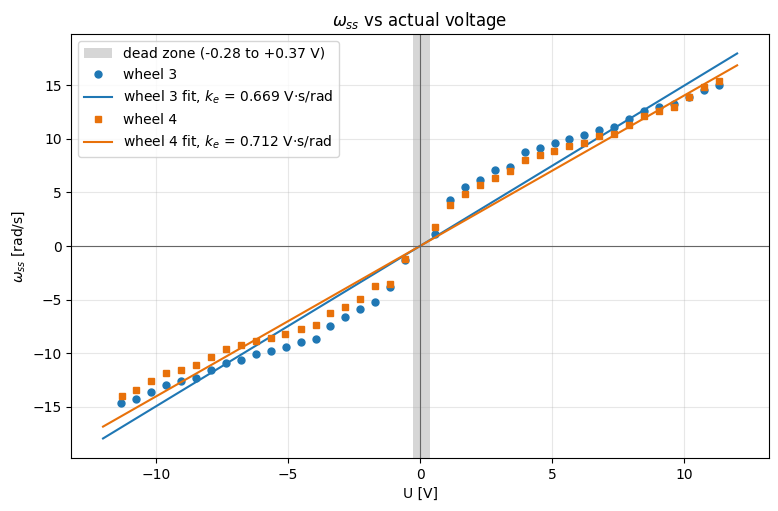

In [6]:
dz_lo = min(dz[w][0] for w in WHEELS)
dz_hi = max(dz[w][1] for w in WHEELS)
U_line = np.linspace(-12, 12, 50)

plt.figure(figsize=(9, 5.5))
plt.axvspan(dz_lo, dz_hi, color="0.6", alpha=0.4, lw=0,
            label=f"dead zone ({dz_lo:+.2f} to {dz_hi:+.2f} V)")
for w in WHEELS:
    r = res[res.wheel == w]
    plt.plot(r.U, r.w_ss, MARKER[w], ms=5, color=COLOR[w], label=f"wheel {w}")
    plt.plot(U_line, U_line / ke[w], "-", lw=1.5, color=COLOR[w],
             label=f"wheel {w} fit, $k_e$ = {ke[w]:.3f} V·s/rad")
plt.axhline(0, color="0.4", lw=0.8)
plt.axvline(0, color="0.4", lw=0.8)
plt.xlabel("U [V]")
plt.ylabel(r"$\omega_{ss}$ [rad/s]")
plt.title(r"$\omega_{ss}$ vs actual voltage")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. Simulation vs measurement

The identified motor for wheel 3 ($k_e$ and median $T_m$ from above) simulated with `odeint` for the 50 % step, next to the measurement.

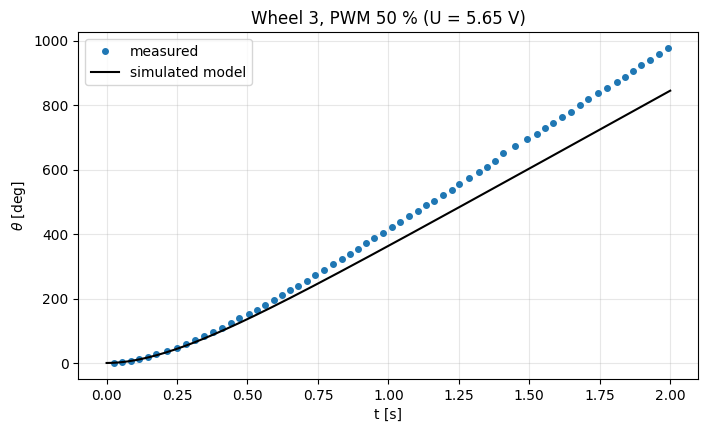

In [7]:
def motor(state, t, U, T_m, k_e):
    omega, theta = state
    return [U / (T_m * k_e) - omega / T_m, omega]


w, p = 3, 50
t, theta, battery = data[(w, p)]
U = p / 100 * battery
t_sim = np.linspace(0, 2, 200)
sim = odeint(motor, [0, 0], t_sim, args=(U, Tm[w], ke[w]))

plt.figure(figsize=(8, 4.5))
plt.plot(t, np.degrees(theta), "o", ms=4, color=COLOR[w], label="measured")
plt.plot(t_sim, np.degrees(sim[:, 1]), "k-", label="simulated model")
plt.xlabel("t [s]")
plt.ylabel(r"$\theta$ [deg]")
plt.title(f"Wheel {w}, PWM {p} % (U = {U:.2f} V)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The shape matches, but the model ends up about 14 % behind: at 50 % the wheel spins at 10.0 rad/s, while $U/k_e$ gives only 8.5 rad/s.

## Discussion

The linear model fails at both ends of the range, because $\omega_{ss}(U)$ is not a straight line: at +10 % the fit predicts 1.7 rad/s while wheel 3 actually spins at 4.3 rad/s, and at +100 % it predicts 17 rad/s instead of 15. $T_m$ is not constant either: it goes from 0.2 to 0.7 s at low PWM down to about 0.05 s at ±100 %, and the dead zone is small (both wheels already turn at ±5 %). At the same PWM wheel 3 spins faster than wheel 4, for example 10.0 vs 9.3 rad/s at +50 % ($k_e$ = 0.669 vs 0.712), and it also reacts more slowly ($T_m$ 0.25 vs 0.18 s), which makes sense because it is the bigger wheel with more inertia. Since wheel 3 is both faster and bigger, the robot will curve towards the wheel 4 side when both motors get the same PWM. For next week's odometry this means I need each wheel's own radius, and if I predict the motion from the motor model, separate parameters for each wheel, otherwise the heading will drift.